# 02 - Extract hand keypoints with MediaPipe (v2)

**Goal:** turn each training image into 63 numbers (21 landmarks x x/y/z) that a small MLP can learn from, and keep the frame number so notebook 03 can do a block split.

**Plan:** (1) one image, drawn  (2) detection rate per class  (3) rescue experiment for missed hands  (4) speed benchmark -> stride  (5) normalization  (6) full run -> `data/processed/`  (7) coverage check for the block split

## Step 1 - One image through MediaPipe (recap)

- Pipeline: `cv2.imread` (BGR) -> `cvtColor` to **RGB** -> `mp.Image(SRGB, ...)` -> `detect()`.
- `result.hand_landmarks` is a list with one entry per hand; **an empty list means no hand** and must become "no sample", not a crash.
- Regular landmarks: `x`/`y` are **fractions of the image** (origin top-left), `z` is relative depth (wrist ~ 0, negative = closer to camera). World landmarks: metres, origin near the hand centre.
- A2.jpg: 1 hand, 21 landmarks, handedness Right (0.86). Checked by eye: right-hand fist, palm to camera, thumb on the image's right side.

In [1]:
import re, time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

TRAIN_DIR = Path("../data/raw/asl_alphabet_train")
MODEL_PATH = "../models/mediapipe/hand_landmarker.task"
CLASSES = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
print(len(CLASSES), "classes")

def make_options(conf=0.5):
    # conf = minimum detection AND presence confidence (MediaPipe's default is 0.5)
    return vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(model_asset_path=MODEL_PATH),
        running_mode=vision.RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=conf,
        min_hand_presence_confidence=conf,
    )

def load_rgb(path):
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def detect(landmarker, rgb):
    """Return the MediaPipe result for one RGB array."""
    return landmarker.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))

def frame_number(path):
    # B1042.jpg -> 1042 (numeric, NOT string order)
    return int(re.search(r"(\d+)", Path(path).stem).group(1))

def sorted_frames(cls):
    return sorted((TRAIN_DIR / cls).glob("*.jpg"), key=frame_number)

29 classes


### Draw the landmarks (letter image vs `nothing` image)
Why: before trusting 87k extractions, confirm the points really sit on the hand. `x` scales with **width**, `y` with **height** (shape is `(H, W, C)`); `cv2.circle` needs integer (x, y) pixels. Draw on a copy so the clean image stays clean.

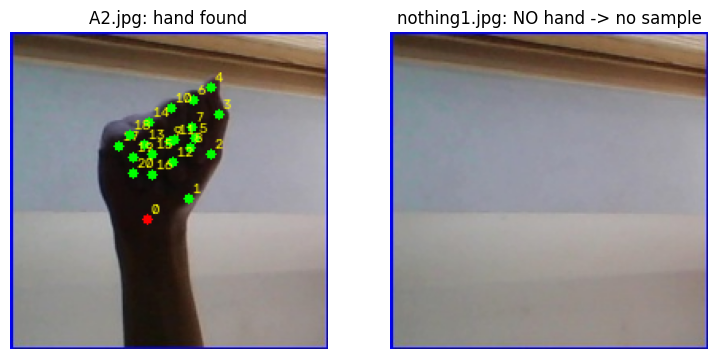

In [2]:
def draw_landmarks(rgb, hand, label_points=True):
    out = rgb.copy()
    H, W = out.shape[:2]
    for i, p in enumerate(hand):
        px, py = int(p.x * W), int(p.y * H)
        colour = (255, 0, 0) if i == 0 else (0, 255, 0)   # wrist red, rest green
        cv2.circle(out, (px, py), 3, colour, -1)
        if label_points:
            cv2.putText(out, str(i), (px + 3, py - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.3, (255, 255, 0), 1)
    return out

paths = [TRAIN_DIR / "A" / "A2.jpg", TRAIN_DIR / "nothing" / "nothing1.jpg"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
with vision.HandLandmarker.create_from_options(make_options()) as lm:
    for ax, path in zip(axes, paths):
        rgb = load_rgb(path)
        res = detect(lm, rgb)
        if res.hand_landmarks:
            ax.imshow(draw_landmarks(rgb, res.hand_landmarks[0]))
            ax.set_title(f"{path.name}: hand found")
        else:
            ax.imshow(rgb)
            ax.set_title(f"{path.name}: NO hand -> no sample")
        ax.axis("off")
plt.show()

**Finding:** the 21 points sit on the fist, with the wrist (0) at the base and the fingertips (4, 8, 12, 16, 20) at the top. The `nothing` image returns an empty list and is handled without a crash.

## Step 2 - Detection rate per class (default settings, confidence 0.5)
Run on an **evenly spaced sample** (every 30th frame, ~100 per class) and record how often a hand is found. `nothing` should fail by design; the surprises are the other classes. Handedness is recorded to settle the mirroring question.

In [3]:
SAMPLE_STRIDE = 30
rows = []
with vision.HandLandmarker.create_from_options(make_options(0.5)) as lm:
    for cls in CLASSES:
        for f in sorted_frames(cls)[::SAMPLE_STRIDE]:
            res = detect(lm, load_rgb(f))
            found = bool(res.hand_landmarks)
            rows.append({"cls": cls, "frame": frame_number(f), "found": found,
                         "hand": res.handedness[0][0].category_name if found else None})

df_rate = pd.DataFrame(rows)
rate = df_rate.groupby("cls")["found"].agg(["mean", "sum", "count"]).rename(columns={"mean": "rate"})
print(rate.sort_values("rate").round(3).to_string())

         rate  sum  count
cls                      
nothing  0.00    0    100
N        0.45   45    100
M        0.51   51    100
space    0.55   55    100
del      0.61   61    100
A        0.70   70    100
P        0.70   70    100
C        0.71   71    100
X        0.71   71    100
Q        0.72   72    100
B        0.73   73    100
O        0.75   75    100
E        0.76   76    100
I        0.78   78    100
Z        0.79   79    100
T        0.79   79    100
G        0.80   80    100
W        0.80   80    100
H        0.81   81    100
U        0.82   82    100
D        0.82   82    100
S        0.84   84    100
L        0.84   84    100
J        0.85   85    100
R        0.85   85    100
Y        0.86   86    100
V        0.87   87    100
K        0.91   91    100
F        0.95   95    100


In [4]:
# Handedness consistency: is it always the same hand label?
print(df_rate[df_rate.found].groupby("cls")["hand"].value_counts(normalize=True).unstack().round(2).fillna(0).to_string())

hand   Left  Right
cls               
A      0.01   0.99
B      0.01   0.99
C      0.25   0.75
D      0.06   0.94
E      0.01   0.99
F      0.03   0.97
G      0.02   0.98
H      0.09   0.91
I      0.00   1.00
J      0.04   0.96
K      0.01   0.99
L      0.00   1.00
M      0.33   0.67
N      0.04   0.96
O      0.17   0.83
P      0.01   0.99
Q      0.08   0.92
R      0.02   0.98
S      0.02   0.98
T      0.03   0.97
U      0.04   0.96
V      0.07   0.93
W      0.01   0.99
X      0.03   0.97
Y      0.01   0.99
Z      0.03   0.97
del    0.30   0.70
space  0.58   0.42


**Findings from my first run:** `nothing` 0% (by design). Weakest: N 45%, M 51%, space 55%, del 61%. Best: F 95%, K 91%. About 27% of frames are lost, and unevenly. Handedness is ~91-100% "Right" for most letters (one signer, one hand), but mixed on near-symmetric shapes (C 25% Left, M 33%, del 30%, space 58%), so the label is unreliable per frame and is **not used as a feature**.

## Step 3 - Rescue experiment: can we recover missed hands?
Three cheap ideas on the weak classes (every 30th frame), plus `nothing` to make sure we don't create false hands:
- **Lower confidence (0.3):** accept the detector's less certain guesses.
- **Pad 50 px:** add a border in case the hand is cropped by the frame edge.
- **Upscale 2x:** in case the hand is too small/blurry at 200x200.

In [5]:
def run_variant(name, conf=0.5, pad=0, scale=1):
    out = {}
    with vision.HandLandmarker.create_from_options(make_options(conf)) as lm:
        for cls in ["N", "M", "A", "space", "nothing"]:
            files = sorted_frames(cls)[::30]
            hits = 0
            for f in files:
                rgb = load_rgb(f)
                if pad:
                    rgb = cv2.copyMakeBorder(rgb, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
                if scale != 1:
                    rgb = cv2.resize(rgb, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
                hits += bool(detect(lm, rgb).hand_landmarks)
            out[cls] = hits / len(files)
    return pd.Series(out, name=name)

variants = [
    run_variant("baseline"),
    run_variant("conf 0.3", conf=0.3),
    run_variant("pad 50px", pad=50),
    run_variant("upscale 2x", scale=2),
    run_variant("pad+conf", conf=0.3, pad=50),
]
print(pd.concat(variants, axis=1).round(2).to_string())

         baseline  conf 0.3  pad 50px  upscale 2x  pad+conf
N            0.45      0.47      0.31        0.36      0.35
M            0.51      0.63      0.36        0.50      0.48
A            0.70      0.76      0.65        0.71      0.69
space        0.55      0.64      0.51        0.47      0.67
nothing      0.00      0.00      0.00        0.00      0.00


**Findings from my first run:** padding and 2x upscaling made things **worse** (N 0.45 -> 0.31/0.36), so they are dropped. Confidence 0.3 gave a modest gain (M +12 points, space +9, A +6, N +2 which is noise at 100 frames) with **no false hands on `nothing`**. Decision: use **confidence 0.3** for the full extraction. The live webcam app must use the same setting, or training and live detection will disagree.

In [6]:
CONF = 0.3          # chosen from the experiment above; reuse this exact value in the webcam app

## Step 4 - Benchmark and choose the frame stride
Measure ms per image (read + detect), then decide how many frames to extract. Inference is CPU-bound, so I stay **sequential with one landmarker**: threads won't help the way they might for file reads, and a landmarker must not be shared across threads.

In [7]:
bench_files = [f for cls in ["A", "B", "L", "M", "Y"] for f in sorted_frames(cls)[::60][:20]]
with vision.HandLandmarker.create_from_options(make_options(CONF)) as lm:
    detect(lm, load_rgb(bench_files[0]))              # warm-up, not timed
    t0 = time.perf_counter()
    for f in bench_files:
        detect(lm, load_rgb(f))
    ms = (time.perf_counter() - t0) / len(bench_files) * 1000

TOTAL = 86_995
print(f"{ms:.1f} ms/image over {len(bench_files)} images")
for stride in [1, 2, 5, 10]:
    n = TOTAL // stride
    print(f"stride {stride:>2}: {n:>6} images -> {n * ms / 1000 / 60:5.1f} min")

16.0 ms/image over 100 images
stride  1:  86995 images ->  23.2 min
stride  2:  43497 images ->  11.6 min
stride  5:  17399 images ->   4.6 min
stride 10:   8699 images ->   2.3 min


**Decision from my first run:** 16.1 ms/image predicted 23.4 min for stride 1 and the real run took 23.6 min, so stride 1 is affordable. Neighbouring frames are near-twins, but small angle changes are useful, so I keep every frame. The block split in notebook 03, not dropping frames, is what protects validation.

## Step 5 - Normalization
**Problem:** regular `x`/`y` are fractions of the *image*, so the same hand shape gives different numbers when the hand is higher, lower, or closer to the camera. The MLP should learn **shape**, not position or size.

**Recipe**
1. Convert to the same units: `x*W`, `y*H`, `z*W` (MediaPipe's `z` uses roughly the same scale as `x`). This matters on the 640x480 webcam; our 200x200 images hide the mistake.
2. **Translate** so the wrist (landmark 0) is the origin -> position stops mattering.
3. **Scale** by hand size = distance from the wrist to the middle-finger knuckle (landmark 9) -> distance from camera stops mattering. I use palm length rather than the largest distance because it changes little when fingers curl.
4. Flatten to 63 numbers.

**Mirroring / handedness:** the dataset looks like one consistently-labelled right hand, and MediaPipe's handedness label is unreliable on symmetric shapes, so it is stored as a diagnostic column only, not used as a feature. Whether to flip live webcam frames is decided **empirically in notebook 04/05**: hold up my right hand and see which label the live frame gets; use whichever setup (raw or flipped) gives mostly "Right", as the dataset does. World landmarks (metric, hand-centred) are a possible later experiment.

In [8]:
def normalize(hand, W, H):
    pts = np.array([[p.x * W, p.y * H, p.z * W] for p in hand], dtype=np.float32)  # (21, 3)
    pts -= pts[0]                                  # wrist -> origin
    scale = np.linalg.norm(pts[9, :2])             # palm length in pixels (x, y only)
    if scale < 1e-6:
        return None                                # degenerate hand -> no sample
    return (pts / scale).reshape(-1)               # (63,)

# Invariance test: same hand drawn smaller and shifted must give the same features
with vision.HandLandmarker.create_from_options(make_options(CONF)) as lm:
    rgb = load_rgb(TRAIN_DIR / "A" / "A2.jpg")
    hand = detect(lm, rgb).hand_landmarks[0]

f1 = normalize(hand, 200, 200)

class P:                                            # fake landmark: shifted + shrunk
    def __init__(self, p): self.x, self.y, self.z = 0.2 + p.x * 0.5, 0.1 + p.y * 0.5, p.z * 0.5
f2 = normalize([P(p) for p in hand], 200, 200)

print("shape:", f1.shape, "| max difference after shift+shrink:", float(np.abs(f1 - f2).max()))
print("wrist features:", f1[:3], "| middle knuckle xy distance:", float(np.linalg.norm(f1[27:29])))

shape: (63,) | max difference after shift+shrink: 3.5762786865234375e-07
wrist features: [0. 0. 0.] | middle knuckle xy distance: 1.0


**Check:** the difference should be about 0 (position and size are gone), the wrist is exactly (0, 0, 0), and the wrist-to-landmark-9 distance is 1.0 by construction. (First run: difference 3e-7.)

## Step 6 - Full extraction
Saves one row per detected hand: class, **frame number** (needed for the block split), handedness, and 63 features. Images with no hand are **not** rows; they are counted per class. The `nothing` class is run only to count false detections and **never saved as training rows**: in the model, "no hand detected" means NOTHING.

In [9]:
STRIDE = 1
OUT_DIR = Path("../data/processed"); OUT_DIR.mkdir(parents=True, exist_ok=True)
TAG = f"conf{int(round(CONF * 10)):02d}_stride{STRIDE}"       # e.g. conf03_stride1
feature_cols = [f"{n}{i}" for i in range(21) for n in "xyz"]

records, fail_counts, total_counts = [], {}, {}
t0 = time.perf_counter()
with vision.HandLandmarker.create_from_options(make_options(CONF)) as lm:
    for cls in CLASSES:
        files = sorted_frames(cls)[::STRIDE]
        fails = 0
        for f in files:
            rgb = load_rgb(f)
            H, W = rgb.shape[:2]
            res = detect(lm, rgb)
            feats = normalize(res.hand_landmarks[0], W, H) if res.hand_landmarks else None
            if feats is None:
                fails += 1
                continue
            if cls == "nothing":                  # false detection: count it, never save it
                continue
            h = res.handedness[0][0]
            records.append([cls, frame_number(f), h.category_name, h.score, *feats])
        fail_counts[cls], total_counts[cls] = fails, len(files)
        print(f"{cls:>8}: {len(files) - fails}/{len(files)} hands found  ({(time.perf_counter() - t0) / 60:.1f} min elapsed)")

df = pd.DataFrame(records, columns=["cls", "frame", "hand", "hand_score", *feature_cols])
df.to_csv(OUT_DIR / f"keypoints_{TAG}.csv", index=False)
pd.DataFrame({"total": total_counts, "failed": fail_counts}).to_csv(OUT_DIR / f"failed_{TAG}.csv")
print(df.shape, "-> saved", f"keypoints_{TAG}.csv")
print("false detections on 'nothing':", total_counts["nothing"] - fail_counts["nothing"], "of", total_counts["nothing"])

       A: 2291/2995 hands found  (0.8 min elapsed)
       B: 2250/3000 hands found  (1.7 min elapsed)
       C: 2119/3000 hands found  (2.6 min elapsed)
       D: 2583/3000 hands found  (3.4 min elapsed)
       E: 2344/3000 hands found  (4.3 min elapsed)
       F: 2907/3000 hands found  (5.2 min elapsed)
       G: 2562/3000 hands found  (6.1 min elapsed)
       H: 2472/3000 hands found  (6.9 min elapsed)
       I: 2473/3000 hands found  (7.8 min elapsed)
       J: 2647/3000 hands found  (8.7 min elapsed)
       K: 2742/3000 hands found  (9.6 min elapsed)
       L: 2599/3000 hands found  (10.5 min elapsed)
       M: 1957/3000 hands found  (11.3 min elapsed)
       N: 1529/3000 hands found  (12.1 min elapsed)
       O: 2349/3000 hands found  (12.9 min elapsed)
       P: 2127/3000 hands found  (13.8 min elapsed)
       Q: 2229/3000 hands found  (14.6 min elapsed)
       R: 2617/3000 hands found  (15.5 min elapsed)
       S: 2640/3000 hands found  (16.3 min elapsed)
       T: 2403/3000 han

In [10]:
# Sanity checks on the saved table
print(df.groupby("cls").size().to_string())
print("NaNs:", int(df[feature_cols].isna().sum().sum()))
print("wrist features all zero:", bool((df[["x0", "y0", "z0"]].abs().max() < 1e-6).all()))
print("miss rate per class (worst 8):")
print((pd.Series(fail_counts) / pd.Series(total_counts)).drop("nothing").sort_values(ascending=False).head(8).round(3))

cls
A        2291
B        2250
C        2119
D        2583
E        2344
F        2907
G        2562
H        2472
I        2473
J        2647
K        2742
L        2599
M        1957
N        1529
O        2349
P        2127
Q        2229
R        2617
S        2640
T        2403
U        2557
V        2596
W        2519
X        2237
Y        2637
Z        2429
del      2042
space    1983
NaNs: 0
wrist features all zero: True
miss rate per class (worst 8):
N        0.490
M        0.348
space    0.339
del      0.319
C        0.294
P        0.291
Q        0.257
X        0.254
dtype: float64


## Step 7 - Does the block split still work?
Notebook 03 trains on frames <= 2100 and validates on frames >= 2300 (200-frame buffer, because near-twin frames stay similar for hundreds of frames). Failed detections may have removed whole stretches, so check that every class has rows in **both** blocks and see how thin validation gets.

In [11]:
cov = pd.DataFrame({
    "total": df.groupby("cls").size(),
    "train(<=2100)": df[df.frame <= 2100].groupby("cls").size(),
    "val(>=2300)": df[df.frame >= 2300].groupby("cls").size(),
})
print(cov.to_string())
print("classes missing from either block:", list(cov[cov.isna().any(axis=1)].index))

       total  train(<=2100)  val(>=2300)
cls                                     
A       2291           1792          301
B       2250           1809          260
C       2119           1773          237
D       2583           2018          384
E       2344           1864          307
F       2907           2031          694
G       2562           1961          402
H       2472           2029          267
I       2473           2060          280
J       2647           2031          418
K       2742           2052          494
L       2599           1997          460
M       1957           1516          279
N       1529           1241          227
O       2349           1984          319
P       2127           1866          175
Q       2229           1931          236
R       2617           2012          447
S       2640           2025          471
T       2403           2016          204
U       2557           1961          424
V       2596           1926          483
W       2519    

## Findings (update after the conf 0.3 run)
- **Detection rate per class** (conf 0.5 sample, then the full conf 0.3 run): weakest classes, best classes, how much the 0.3 setting recovered.
- **`nothing`:** false detections at conf 0.3 (the experiment showed 0 in the sample). "No hand detected" = NOTHING in the model, and the live app inherits the same misses, so M and N will be weakest live.
- **J/Z:** detected about as well as other letters as stills; their motion is invisible, so expect confusions.
- **Benchmark and stride:** ms/image, predicted vs actual time, why stride 1.
- **Handedness:** mostly "Right" except on symmetric shapes (C, M, O, del, space); not a feature.
- **Normalization:** wrist origin + palm-length scale; shift+shrink difference ~0.
- **Class imbalance:** rows per class from the coverage table (smallest vs largest), and the thinnest validation classes.
- **Mistakes kept:** used `create_from_file` first; counted world landmarks as "landmarks"; believed regular landmarks originate at the wrist (only `z` does); assumed the webcam should be flipped before testing it.